# Part 2 — stopping-reason error analysis

Analyze only validation label=0 trials. Match Part 2 trial_id to Part 1 ID, preserve multi-label groups, use valid truth before predictions, and distinguish no record from unresolved masked labels. The historical baseline analysis has 131 unresolved phase rows / 113 unique trials. Full mode regenerates the baseline and established Part 1 test predictions from CSVs, without filling any additional masked labels.

This notebook embeds the source implementation; it does not import project-specific Python modules. Standard-library and third-party imports are sufficient. Run cells in order from a fresh kernel. Default verification mode reads explicitly labeled historical references without fitting. Set `RUN_FULL=True` for fresh computation. All generated outputs are isolated under `part2/notebook_reproduction/`.


## Imports, paths, execution mode and preservation checks


In [1]:
from pathlib import Path
import os
import hashlib
import json
# Configure numerical thread limits before NumPy/scikit-learn are imported.
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
ROOT = Path.cwd().resolve()
if ROOT.name == 'part2':
    ROOT = ROOT.parent
if not all((ROOT / name).is_dir() for name in ('part1-data', 'part2-data')):
    raise FileNotFoundError('Start the notebook from the repository root or its part2/ directory.')
REPRO_ROOT = ROOT / 'part2' / 'notebook_reproduction'
RUN_FULL = False  # Change to True for fresh complete training; verify mode never fits models.
# Original artifacts are read-only references. Every newly generated artifact stays below REPRO_ROOT.
def protected_hashes():
    paths = []
    for directory in ('part1-data', 'part2-data', 'outputs', 'part1-results', 'part2-results',
                      'part2/outputs', 'part2/calibration_outputs', 'writeup'):
        if (ROOT / directory).exists():
            paths.extend(p for p in (ROOT / directory).rglob('*') if p.is_file())
    paths.extend(ROOT.glob('*.py'))
    paths.extend((ROOT / 'part2').glob('*.py'))
    return {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
ORIGINAL_HASHES = protected_hashes()
print('Mode:', 'full fresh reproduction' if RUN_FULL else 'verification only — no model fitting')


Mode: verification only — no model fitting


In [2]:
DATA = ROOT / 'part2-data'
OUTPUT = REPRO_ROOT / 'part2_modeling'
REFERENCE_OUTPUT = ROOT / 'part2' / 'outputs'
REFERENCE_CALIBRATION = ROOT / 'part2' / 'calibration_outputs'
SEED = 5785
PHASES = ('I', 'II', 'III')
TEXT_SETS = {
    'clinical': ('diseases_cleaned', 'drugs', 'icdcodes'),
    'criteria': ('criteria',),
    'all_text': ('criteria', 'diseases_cleaned', 'drugs', 'icdcodes'),
}
CS = (0.1, 1.0, 10.0)
THRESHOLD = 0.5
OUTPUT.mkdir(parents=True, exist_ok=True)


In [3]:
import ast
import re
import pandas as pd


In [4]:
TEXT_COLUMNS = ('criteria', 'diseases_cleaned', 'drugs', 'icdcodes')


### `load_data`

Implementation copied from `part2/data.py`.


In [5]:
def load_data():
    names = ('outcome_train', 'outcome_val', 'outcome_test', 'part2_sample_submission')
    missing = [str(DATA / f'{n}.csv') for n in names if not (DATA / f'{n}.csv').exists()]
    if missing:
        raise FileNotFoundError(f'Missing files: {missing}')
    train, val, test, sample = [pd.read_csv(DATA / f'{n}.csv') for n in names]
    for frame, expected in zip((train, val, test), (8037, 1013, 1500)):
        assert len(frame) == expected
        assert frame.ID.is_unique and frame.ID.notna().all()
        assert frame.trial_id.notna().all()
        assert set(frame.phase) == set(PHASES)
        assert not frame.duplicated(['trial_id', 'phase']).any()
        assert frame.ID.eq(frame.trial_id + '_' + frame.phase).all()
        assert set(TEXT_COLUMNS + ('start_year',)).issubset(frame.columns)
    for frame in (train, val):
        assert set(frame.label) == {0, 1}
        assert frame.groupby('trial_id').label.nunique().max() == 1
    for a, b in ((train, val), (train, test), (val, test)):
        assert not set(a.trial_id).intersection(b.trial_id), 'Cross-split trial leakage'
    assert sample.ID.equals(test.ID)
    assert list(sample.columns) == ['ID', 'label']
    return train, val, test, sample


### `flatten`

Implementation copied from `part2/data.py`.


In [6]:
def flatten(value):
    """Decode nested Python-list strings safely (including nested ICD lists)."""
    if isinstance(value, (list, tuple)):
        return ' '.join(flatten(v) for v in value)
    if pd.isna(value):
        return ''
    value = str(value).strip()
    if value.startswith('['):
        try:
            return flatten(ast.literal_eval(value))
        except (ValueError, SyntaxError):
            pass
    return re.sub(r'\s+', ' ', value).strip()


### `prepare`

Implementation copied from `part2/data.py`.


In [7]:
def prepare(frame):
    # Explicit allowlist: IDs, labels, reason labels/embeddings never enter features.
    result = frame[list(TEXT_COLUMNS) + ['phase', 'start_year']].copy()
    for col in TEXT_COLUMNS:
        result[col] = result[col].map(flatten)
    return result


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


### `build_features`

Implementation copied from `part2/features.py`.


In [9]:
def build_features(text_columns, use_year, pooled):
    transformers = []
    for col in text_columns:
        transformers.append((col, TfidfVectorizer(
            lowercase=True, strip_accents='unicode', ngram_range=(1, 2),
            min_df=3, max_df=1.0, sublinear_tf=True,
            # Preserve decimal ICD codes as tokens, including one-character words.
            token_pattern=r'(?u)\b\w[\w.]*\b',
            max_features=15000 if col == 'criteria' else 5000), col))
    if pooled:
        transformers.append(('phase', OneHotEncoder(handle_unknown='ignore'), ['phase']))
    if use_year:
        transformers.append(('year', Pipeline([
            ('impute', SimpleImputer(strategy='median', add_indicator=True)),
            ('scale', StandardScaler()),
        ]), ['start_year']))
    return ColumnTransformer(transformers, remainder='drop', sparse_threshold=1.0)


In [10]:
import numpy as np
from sklearn.linear_model import LogisticRegression


### `fit_features`

Implementation copied from `part2/training.py`.


In [11]:
def fit_features(train, val, text_columns, use_year, regime):
    groups = ('pooled',) if regime == 'pooled' else PHASES
    prepared = {}
    for group in groups:
        tm = np.ones(len(train), dtype=bool) if group == 'pooled' else train.phase.eq(group).to_numpy()
        vm = np.ones(len(val), dtype=bool) if group == 'pooled' else val.phase.eq(group).to_numpy()
        features = build_features(text_columns, use_year, regime == 'pooled')
        xt = features.fit_transform(train.loc[tm])
        xv = features.transform(val.loc[vm])
        prepared[group] = (features, xt, xv, tm, vm)
    return prepared


### `fit_classifiers`

Implementation copied from `part2/training.py`.


In [12]:
def fit_classifiers(prepared, labels, c):
    train_p = np.empty(len(labels))
    val_p = np.empty(sum(int(v[4].sum()) for v in prepared.values()))
    models = {}
    for group, (features, xt, xv, tm, vm) in prepared.items():
        model = LogisticRegression(C=c, solver='liblinear', max_iter=2000, tol=1e-5, random_state=SEED)
        model.fit(xt, labels[tm])
        if model.n_iter_.max() >= model.max_iter:
            raise RuntimeError(f'Nonconvergence for {group}, C={c}')
        train_p[tm] = model.predict_proba(xt)[:, 1]
        val_p[vm] = model.predict_proba(xv)[:, 1]
        models[group] = dict(features=features, classifier=model)
    return models, train_p, val_p


### `predict`

Implementation copied from `part2/training.py`.


In [13]:
def predict(bundle, frame):
    if bundle['kind'] == 'prior':
        return frame.phase.map(bundle['priors']).to_numpy(dtype=float)
    p = np.empty(len(frame))
    for group, components in bundle['models'].items():
        mask = np.ones(len(frame), dtype=bool) if group == 'pooled' else frame.phase.eq(group).to_numpy()
        if mask.any():
            x = components['features'].transform(frame.loc[mask])
            p[mask] = components['classifier'].predict_proba(x)[:, 1]
    return p


In [14]:
import numpy as np
from sklearn.metrics import log_loss, f1_score, roc_auc_score, average_precision_score


### `evaluate`

Implementation copied from `part2/evaluation.py`.


In [15]:
def evaluate(frame, probabilities):
    p = np.asarray(probabilities, dtype=float)
    if p.shape != (len(frame),) or not np.isfinite(p).all() or not ((p >= 0) & (p <= 1)).all():
        raise ValueError('Expected one finite probability per row in [0, 1]')
    result = {}
    for phase in ('overall', *PHASES):
        mask = np.ones(len(frame), dtype=bool) if phase == 'overall' else frame.phase.eq(phase).to_numpy()
        y, pred = frame.label.to_numpy()[mask], p[mask]
        result[f'{phase}_n'] = len(y)
        if not len(y):
            for metric in ('log_loss', 'f1', 'roc_auc', 'average_precision'):
                result[f'{phase}_{metric}'] = np.nan
            continue
        result[f'{phase}_log_loss'] = log_loss(y, pred, labels=[0, 1])
        result[f'{phase}_f1'] = f1_score(y, pred >= THRESHOLD, zero_division=0)
        both = len(np.unique(y)) == 2
        result[f'{phase}_roc_auc'] = roc_auc_score(y, pred) if both else np.nan
        result[f'{phase}_average_precision'] = average_precision_score(y, pred) if both else np.nan
    result['phase_macro_log_loss'] = np.mean([result[f'{p}_log_loss'] for p in PHASES])
    return result


In [16]:
import pickle
import numpy as np
import pandas as pd


### `validate_submission`

Implementation copied from `part2/submission.py`.


In [17]:
def validate_submission(submission, test, sample):
    assert list(submission.columns) == ['ID', 'label']
    assert len(submission) == len(test) == 1500
    assert submission.ID.equals(test.ID) and submission.ID.equals(sample.ID)
    assert submission.ID.is_unique and not submission.isna().any().any()
    assert np.isfinite(submission.label).all() and submission.label.between(0, 1).all()


### `generate`

Implementation copied from `part2/submission.py`.


In [18]:
def generate(bundle, test, sample):
    submission = pd.DataFrame({'ID': test.ID, 'label': predict(bundle, prepare(test))})
    validate_submission(submission, test, sample)
    path = OUTPUT / 'part2_submission.csv'
    submission.to_csv(path, index=False)
    validate_submission(pd.read_csv(path), test, sample)
    return path


In [19]:
DATA_DIR = ROOT / 'part1-data'
OUTPUT_DIR = REPRO_ROOT / 'part1'
TRAIN_PATH = DATA_DIR / 'part1_train.csv'
VAL_PATH = DATA_DIR / 'part1_val.csv'
TEST_PATH = DATA_DIR / 'part1_test.csv'
RANDOM_STATE = 42
LABELS = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']
FEATURES = [f'emb_{i}' for i in range(150)]
K = 8
SMOOTHING = 5.0
LOW_CONFIDENCE = 0.2
HIGH_CONFIDENCE = 0.8
MIN_LABELED_CLUSTER = 5
PSEUDO_WEIGHT = 0.3
SUBMISSION_THRESHOLDS = [0.20, 0.20, 0.20, 0.40, 0.40]


In [20]:
from dataclasses import dataclass
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler


### `Dataset`

Implementation copied from `data_utils.py`.


In [21]:
@dataclass
class Dataset:
    train: pd.DataFrame
    val: pd.DataFrame
    scaler: StandardScaler
    X_train: np.ndarray
    X_val: np.ndarray
    X_labeled: np.ndarray
    X_unlabeled: np.ndarray
    y_labeled: np.ndarray
    y_val: np.ndarray
    labeled_mask: np.ndarray
    unlabeled_mask: np.ndarray


### `load_data`

Implementation copied from `data_utils.py`.


In [22]:
def load_reason_data():
    train = pd.read_csv(TRAIN_PATH)
    val = pd.read_csv(VAL_PATH)
    labeled_mask = (train[LABELS] != -100).all(axis=1).to_numpy()
    unlabeled_mask = (train[LABELS] == -100).all(axis=1).to_numpy()
    if not np.all(labeled_mask | unlabeled_mask):
        raise ValueError("Some training rows have partially missing labels.")
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train[FEATURES])
    X_val = scaler.transform(val[FEATURES])
    return Dataset(
        train, val, scaler, X_train, X_val,
        X_train[labeled_mask], X_train[unlabeled_mask],
        train.loc[labeled_mask, LABELS].to_numpy(dtype=int),
        val[LABELS].to_numpy(dtype=int), labeled_mask, unlabeled_mask,
    )


### `load_test`

Implementation copied from `data_utils.py`.


In [23]:
def load_test(scaler):
    test = pd.read_csv(TEST_PATH)
    return test, scaler.transform(test[FEATURES])


In [24]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.svm import SVC


### `train_ovr`

Implementation copied from `models.py`.


In [25]:
def train_ovr(X, y, sample_weight=None):
    models = []
    for j in range(y.shape[1]):
        model = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
        model.fit(X, y[:, j], sample_weight=sample_weight)
        models.append(model)
    return models


### `predict_probabilities`

Implementation copied from `models.py`.


In [26]:
def predict_probabilities(models, X):
    return np.column_stack([model.predict_proba(X)[:, 1] for model in models])


### `predict_labels`

Implementation copied from `models.py`.


In [27]:
def predict_labels(probabilities, thresholds=0.5, ensure_one=False):
    predictions = (probabilities >= np.asarray(thresholds)).astype(int)
    if ensure_one:
        empty = np.flatnonzero(predictions.sum(axis=1) == 0)
        predictions[empty, np.argmax(probabilities[empty], axis=1)] = 1
    return predictions


In [28]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture


### `estimate_cluster_labels`

Implementation copied from `pseudo_labeling.py`.


In [29]:
def estimate_cluster_labels(labeled_clusters, y_labeled, K, smoothing=SMOOTHING):
    prior = y_labeled.mean(axis=0)
    cluster_probs = np.zeros((K, len(LABELS)))
    cluster_counts = np.zeros(K, dtype=int)
    for k in range(K):
        mask = labeled_clusters == k
        count = int(mask.sum())
        cluster_counts[k] = count
        positive_counts = y_labeled[mask].sum(axis=0)
        cluster_probs[k] = (positive_counts + smoothing * prior) / (count + smoothing)
    return cluster_probs, cluster_counts


### `augment_and_train`

Implementation copied from `pseudo_labeling.py`.


In [30]:
def augment_and_train(X_labeled, y_labeled, pseudo_X, pseudo_y, weight=PSEUDO_WEIGHT):
    X_aug = np.vstack([X_labeled, pseudo_X])
    y_aug = np.vstack([y_labeled, pseudo_y])
    weights = np.concatenate([np.ones(len(y_labeled)), np.full(len(pseudo_y), weight)])
    return train_ovr(X_aug, y_aug, sample_weight=weights)


### `fit_kmeans_pseudo`

Implementation copied from `pseudo_labeling.py`.


In [31]:
def fit_kmeans_pseudo(data, K=8):
    km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
    cluster_ids = km.fit_predict(data.X_train)
    labeled_clusters = cluster_ids[data.labeled_mask]
    unlabeled_clusters = cluster_ids[data.unlabeled_mask]
    cluster_probs, cluster_counts = estimate_cluster_labels(labeled_clusters, data.y_labeled, K)
    pseudo_probs = cluster_probs[unlabeled_clusters]
    confident = ((pseudo_probs <= LOW_CONFIDENCE) | (pseudo_probs >= HIGH_CONFIDENCE)).all(axis=1)
    confident &= cluster_counts[unlabeled_clusters] >= MIN_LABELED_CLUSTER
    pseudo_y = (pseudo_probs[confident] >= HIGH_CONFIDENCE).astype(int)
    models = augment_and_train(data.X_labeled, data.y_labeled, data.X_unlabeled[confident], pseudo_y)
    return {
        "models": models, "clusterer": km, "cluster_probs": cluster_probs,
        "cluster_counts": cluster_counts, "unlabeled_clusters": unlabeled_clusters,
        "pseudo_probs": pseudo_probs, "confident": confident, "pseudo_y": pseudo_y,
    }


In [32]:
import argparse
import numpy as np
import pandas as pd


### `make_submission`

Implementation copied from `submission.py`.


In [33]:
def make_submission(test, probabilities, thresholds=SUBMISSION_THRESHOLDS, ensure_one=True):
    preds = predict_labels(probabilities, thresholds, ensure_one=ensure_one)
    predicted_labels = [" ".join(label for label, positive in zip(LABELS, row) if positive) for row in preds]
    submission = pd.DataFrame({"ID": test["ID"], "Predicted": predicted_labels})
    assert submission["ID"].notna().all() and submission["ID"].is_unique
    assert submission["Predicted"].notna().all()
    assert (submission["Predicted"].str.len() > 0).all(), "Kaggle rejects empty predictions."
    assert all(set(s.split()).issubset(set(LABELS)) for s in submission["Predicted"])
    return submission, preds


## Analysis-only reason matching and group summaries

Embeddings below belong exclusively to the Part 1 reproduction needed to regenerate its test predictions; they never enter the Part 2 feature allowlist. The historical analysis used saved Part 1 predictions. Full mode makes the same predictions afresh using the identical source implementation. Unlabeled Part 1 training rows remain unresolved in the analysis.


In [34]:
import json
import pandas as pd


### `markdown_table`

Implementation copied from `part2/report.py`.


In [35]:
def markdown_table(frame):
    def fmt(v):
        return f'{v:.5f}' if isinstance(v, float) else str(v)
    return '\n'.join(['| ' + ' | '.join(map(str, frame.columns)) + ' |',
                      '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |',
                      *['| ' + ' | '.join(fmt(v) for v in row) + ' |' for row in frame.itertuples(index=False, name=None)]])


In [36]:
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd


In [37]:
REASONS = ('Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other')
NO_REASON = 'no recorded stopping reason'
UNAVAILABLE = 'matched Part 1 record; reasons unavailable'


### `build_reason_table`

Implementation copied from `part2/error_analysis.py`.


In [38]:
def build_reason_table(parts, predictions):
    """Prefer complete true labels, then saved predictions, else retain unknowns."""
    records = []
    for split, frame in parts.items():
        assert frame.ID.str.fullmatch(r'TR\d+').all() and frame.ID.is_unique
        for _, row in frame.iterrows():
            values = row[list(REASONS)] if set(REASONS) <= set(frame.columns) else pd.Series([-100] * 5)
            assert values.isin([0, 1, -100]).all()
            valid = values.isin([0, 1]).all()
            assert valid or values.eq(-100).all(), 'Unexpected partial reason labels'
            records.append(dict(trial_id=row.ID, part1_split=split,
                                reason_source='ground_truth' if valid else 'unavailable',
                                **{r: int(values.iloc[i]) if valid else pd.NA for i, r in enumerate(REASONS)}))
    reasons = pd.DataFrame(records).set_index('trial_id')
    assert reasons.index.is_unique, 'Part 1 split IDs must be disjoint'
    assert predictions.ID.is_unique and predictions.ID.str.fullmatch(r'TR\d+').all()
    assert set(predictions.ID) == set(parts['test'].ID), 'Saved submission must cover actual Part 1 test IDs'
    for row in predictions.itertuples(index=False):
        assert isinstance(row.Predicted, str) and row.Predicted.strip()
        labels = row.Predicted.split()
        assert set(labels) <= set(REASONS) and len(labels) == len(set(labels))
        if reasons.loc[row.ID, 'reason_source'] != 'ground_truth':
            reasons.loc[row.ID, 'reason_source'] = 'prediction'
            for reason in REASONS:
                reasons.loc[row.ID, reason] = int(reason in labels)
    for reason in REASONS:
        reasons[reason] = reasons[reason].astype('Int64')
    return reasons.reset_index()


### `match_unsuccessful`

Implementation copied from `part2/error_analysis.py`.


In [39]:
def match_unsuccessful(validation, outcome, reasons):
    assert validation.ID.is_unique and not validation.duplicated(['trial_id', 'phase']).any()
    assert validation.trial_id.str.fullmatch(r'TR\d+').all()
    assert validation.ID.eq(validation.trial_id + '_' + validation.phase).all()
    assert set(validation.phase) == set(PHASES)
    assert validation.label.isin([0, 1]).all()
    assert np.isfinite(validation.probability).all() and validation.probability.between(0, 1).all()
    assert validation.predicted_label.eq((validation.probability >= THRESHOLD).astype(int)).all()
    # Verify saved predictions against the actual outcome validation split, not ID format alone.
    check = validation.merge(outcome[['ID', 'trial_id', 'phase', 'label']], on='ID',
                             suffixes=('', '_actual'), validate='one_to_one', how='outer', indicator=True)
    assert check._merge.eq('both').all()
    for col in ('trial_id', 'phase', 'label'):
        assert check[col].eq(check[col + '_actual']).all()
    unsuccessful = validation.loc[validation.label.eq(0)].copy()
    joined = unsuccessful.merge(reasons, on='trial_id', how='left', validate='many_to_one', indicator=True)
    joined['part1_match'] = joined.pop('_merge').eq('both')
    joined['reason_source'] = joined.reason_source.fillna('no_record')
    joined['part1_split'] = joined.part1_split.fillna('none')
    assert not joined.duplicated(['trial_id', 'phase']).any()
    return joined


### `summarize`

Implementation copied from `part2/error_analysis.py`.


In [40]:
def summarize(group):
    n = len(group)
    fp = int(group.predicted_label.sum())
    return dict(n_trials=n, n_predicted_success=fp,
                false_success_rate=fp / n if n else np.nan,
                mean_predicted_success_probability=float(group.probability.mean()) if n else np.nan,
                n_ground_truth=int(group.reason_source.eq('ground_truth').sum()),
                n_predictions=int(group.reason_source.eq('prediction').sum()),
                n_no_record=int(group.reason_source.eq('no_record').sum()),
                n_reasons_unavailable=int(group.reason_source.eq('unavailable').sum()))


### `summarize_groups`

Implementation copied from `part2/error_analysis.py`.


In [41]:
def summarize_groups(joined):
    rows, coverage, unresolved, source_rows = [], [], [], []
    for phase in PHASES:
        phase_rows = joined.loc[joined.phase.eq(phase)]
        coverage.append(dict(phase=phase, **summarize(phase_rows)))
        unresolved.append(dict(phase=phase, reason_group=UNAVAILABLE,
                               **summarize(phase_rows.loc[phase_rows.reason_source.eq('unavailable')])))
        for reason in (*REASONS, NO_REASON):
            mask = ~phase_rows.part1_match if reason == NO_REASON else phase_rows[reason].eq(1).fillna(False)
            group = phase_rows.loc[mask]
            rows.append(dict(phase=phase, reason_group=reason, **summarize(group)))
            for source in ('ground_truth', 'prediction', 'no_record'):
                source_rows.append(dict(phase=phase, reason_group=reason, reason_source=source,
                                        **summarize(group.loc[group.reason_source.eq(source)])))
    return tuple(pd.DataFrame(r) for r in (rows, coverage, unresolved, source_rows))


In [42]:
ANALYSIS_OUTPUT = REPRO_ROOT / 'part2_error_analysis'
ANALYSIS_OUTPUT.mkdir(parents=True, exist_ok=True)
parts = {s: pd.read_csv(ROOT / 'part1-data' / f'part1_{s}.csv') for s in ('train','val','test')}
train, outcome, test, sample = load_data()
if RUN_FULL:
    # Same full-training winner; one fit only, not a repeated research grid.
    prepared = fit_features(prepare(train), prepare(outcome), ('criteria',), False, 'pooled')
    models, _, pv = fit_classifiers(prepared, train.label.to_numpy(), 1.0)
    validation = outcome[['ID','trial_id','phase','label']].copy()
    validation['probability'] = pv
    validation['predicted_label'] = (pv >= THRESHOLD).astype(int)
    reason_data = load_reason_data()
    reason_fit = fit_kmeans_pseudo(reason_data, K=K)
    reason_test, reason_x = load_test(reason_data.scaler)
    predictions, _ = make_submission(reason_test, predict_probabilities(reason_fit['models'], reason_x))
else:
    print('Analysis freshly computed from explicitly selected historical prediction files; no training.')
    validation = pd.read_csv(REFERENCE_OUTPUT / 'best_validation_predictions.csv')
    predictions = pd.read_csv(ROOT / 'outputs' / 'part1_submission.csv')
reasons = build_reason_table(parts, predictions)
joined = match_unsuccessful(validation, outcome, reasons)
groups, coverage, unresolved, sources = summarize_groups(joined)
for name, frame in dict(groups=groups, coverage=coverage, unresolved=unresolved,
                        by_source=sources, trial_audit=joined, reason_lookup=reasons).items():
    frame.to_csv(ANALYSIS_OUTPUT / f'stopping_reason_{name}.csv', index=False)
display(groups)
display(coverage)
display(unresolved)


Analysis freshly computed from explicitly selected historical prediction files; no training.


,phase,reason_group,n_trials,n_predicted_success,false_success_rate,mean_predicted_success_probability,n_ground_truth,n_predictions,n_no_record,n_reasons_unavailable
0,I,Safety,2,1,0.500000,0.521100,1,1,0,0
1,I,Funding,1,0,0.000000,0.452208,1,0,0,0
2,I,Efficacy,0,0,NaN,NaN,0,0,0,0
3,I,Recruitment,7,2,0.285714,0.366358,2,5,0,0
4,I,Other,3,2,0.666667,0.557456,0,3,0,0
5,I,no recorded stopping reason,28,13,0.464286,0.474435,0,0,28,0
6,II,Safety,5,3,0.600000,0.522562,1,4,0,0
7,II,Funding,2,0,0.000000,0.369409,1,1,0,0
8,II,Efficacy,3,1,0.333333,0.420943,0,3,0,0
9,II,Recruitment,31,6,0.193548,0.345150,12,19,0,0


,phase,n_trials,n_predicted_success,false_success_rate,mean_predicted_success_probability,n_ground_truth,n_predictions,n_no_record,n_reasons_unavailable
0,I,64,28,0.437500,0.465395,4,7,28,25
1,II,265,78,0.294340,0.407016,16,27,144,78
2,III,123,78,0.634146,0.555062,7,6,82,28


,phase,reason_group,n_trials,n_predicted_success,false_success_rate,mean_predicted_success_probability,n_ground_truth,n_predictions,n_no_record,n_reasons_unavailable
0,I,matched Part 1 record; reasons unavailable,25,11,0.440000,0.470333,0,0,0,25
1,II,matched Part 1 record; reasons unavailable,78,15,0.192308,0.390716,0,0,0,78
2,III,matched Part 1 record; reasons unavailable,28,18,0.642857,0.567909,0,0,0,28


## Verify membership, denominators and historical results


In [43]:
assert len(joined) == 452 and joined.trial_id.nunique() == 398
unknown = joined.loc[joined.reason_source.eq('unavailable')]
assert len(unknown) == 131 and unknown.trial_id.nunique() == 113
assert len(groups) == 18
assert coverage.n_trials.sum() == len(joined)
assert not joined.duplicated(['trial_id','phase']).any()
for row in groups.itertuples(index=False):
    members = [r for r in joined.to_dict('records') if r['phase'] == row.phase and
               ((not r['part1_match']) if row.reason_group == NO_REASON else
                (not pd.isna(r[row.reason_group]) and r[row.reason_group] == 1))]
    assert len(members) == row.n_trials
    assert sum(r['probability'] >= .5 for r in members) == row.n_predicted_success
    if members:
        assert np.isclose(row.false_success_rate, row.n_predicted_success/len(members))
        assert np.isclose(row.mean_predicted_success_probability,
                          np.mean([r['probability'] for r in members]))
    else:
        assert pd.isna(row.false_success_rate)
reference_path = REFERENCE_OUTPUT / 'stopping_reason_groups.csv'
if reference_path.exists():
    reference = pd.read_csv(reference_path)
    assert groups[['phase','reason_group']].equals(reference[['phase','reason_group']])
    assert np.allclose(groups.select_dtypes('number'), reference.select_dtypes('number'), equal_nan=True, atol=1e-6)


## Phase-specific comparisons and coverage figures

Group counts overlap for multi-label reasons. Bar labels show denominators to make fragile small groups visible. Empty groups have undefined rates.


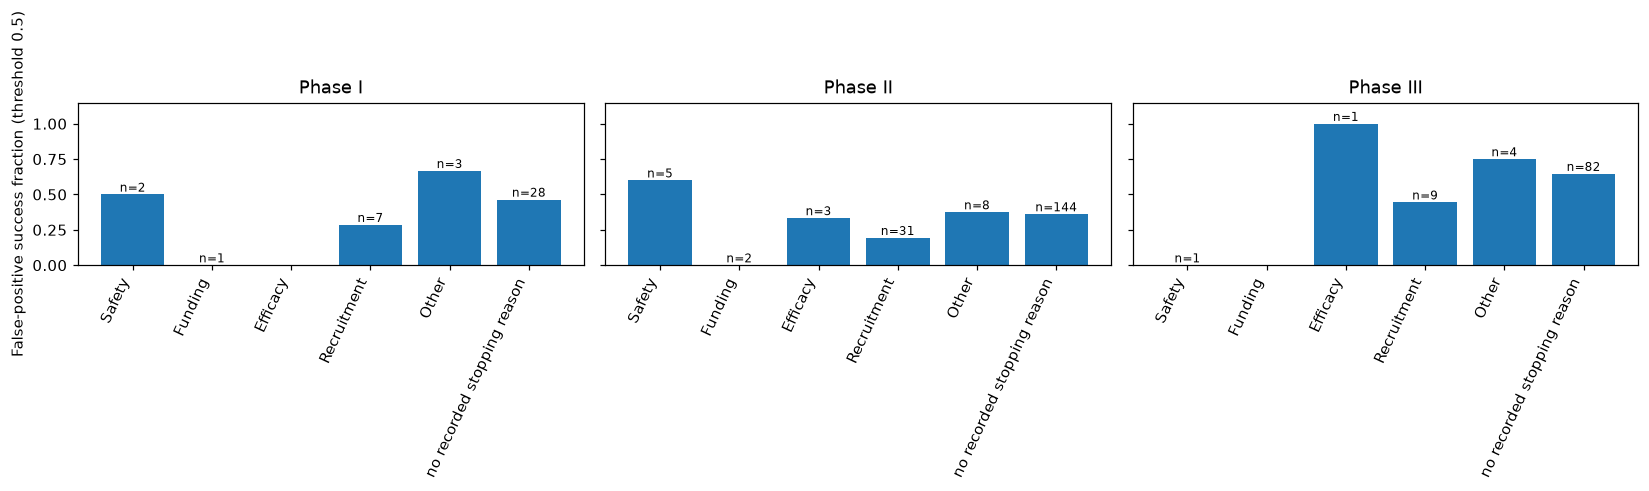

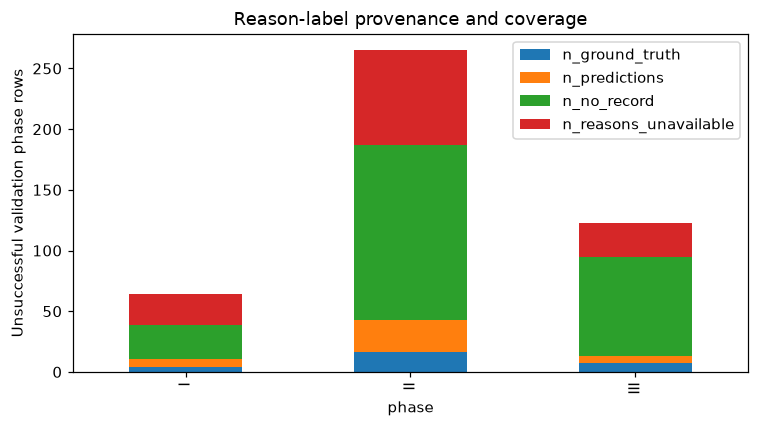

In [44]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, phase in zip(axes, PHASES):
    table = groups.loc[groups.phase.eq(phase)]
    values = table.false_success_rate.to_numpy(dtype=float)
    ax.bar(range(len(table)), values)
    ax.set_xticks(range(len(table)), table.reason_group, rotation=65, ha='right')
    for i, row in enumerate(table.itertuples(index=False)):
        if row.n_trials:
            ax.text(i, row.false_success_rate+.02, f'n={row.n_trials}', ha='center', fontsize=8)
    ax.set(title=f'Phase {phase}', ylim=(0, 1.15))
axes[0].set_ylabel('False-positive success fraction (threshold 0.5)')
fig.tight_layout()
fig.savefig(ANALYSIS_OUTPUT / 'reason_error_rates.png', dpi=140)
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
coverage.set_index('phase')[['n_ground_truth','n_predictions','n_no_record','n_reasons_unavailable']].plot.bar(stacked=True, ax=ax)
ax.set(ylabel='Unsuccessful validation phase rows', title='Reason-label provenance and coverage')
fig.tight_layout()
fig.savefig(ANALYSIS_OUTPUT / 'reason_coverage.png', dpi=140)
plt.show()


## Interpretation

The highest observed fractions are Phase I Other (2/3), Phase II Safety (3/5), and Phase III Efficacy (1/1), all small groups. Phase III no-recorded-reason has 53/82 false successes (64.6%), a larger descriptive group. The 131 unresolved rows are not no-record trials and cannot be assigned to categories. Predicted reasons add uncertainty; categories overlap and phase definitions differ. This analysis alone does not demonstrate probability overconfidence. The calibration notebook tests that separately.


In [45]:
after = protected_hashes()
assert all(after.get(path) == digest for path, digest in ORIGINAL_HASHES.items())
print('Existing source files, data, models, reports, predictions and submissions are unchanged.')


Existing source files, data, models, reports, predictions and submissions are unchanged.
